# Семинар. Нейрон и сеть прямого распространения

**Курс:** «Интеллектуальный анализ текстов: от статистических моделей языка до языковых агентов». Семинар к лекции «Нейронные сети: от нейрона до seq2seq с вниманием» (модуль 2).

## О чём блокнот

Блокнот показывает на числах и рисунках, как устроен один нейрон, почему одного нейрона мало и как сеть из нескольких нейронов обучается по данным. Весь код выполняется на процессоре за одну-две минуты.

| Часть | Содержание |
|---|---|
| 1 | Нейрон: взвешенная сумма и функция активации |
| 2 | Функции активации и их производные |
| 3 | Нейрон как прямая на плоскости |
| 4 | Логические функции AND, OR, XOR |
| 5 | Прямой проход сети в матричном виде, softmax |
| 6 | Функция потерь и граф вычислений |
| 7 | Обучение сети в PyTorch на двумерных данных |
| 8 | Скорость обучения и переобучение |

In [1]:
import json
import random
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import torch
import torch.nn as nn
import torch.nn.functional as F

warnings.filterwarnings("ignore")
torch.set_num_threads(4)

SEED = 42
BLUE, ORANGE, MUTED, GRID = "#2a78d6", "#eb6834", "#6b7280", "#e5e7eb"
GREEN, VIOLET = "#1baf7a", "#6250d6"
# расходящаяся шкала: синий (класс 0), серый (0.5), оранжевый (класс 1)
DIV = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#cfe0f7", "#f0f0ee", "#f9d5c5", "#eb6834"])
SEQ = LinearSegmentedColormap.from_list("seq", ["#f6f9fe", "#cde2fb", "#6da7ec", "#256abf", "#0d366b"])
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.titleweight": "bold"})


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
set_seed()
print("Готово, PyTorch", torch.__version__)

Готово, PyTorch 2.10.0+cpu


## Часть 1. Нейрон

Нейрон получает на вход вектор чисел $x=(x_1,\dots,x_n)$. У нейрона есть вектор весов $w=(w_1,\dots,w_n)$ и смещение $b$. Сначала вычисляется взвешенная сумма входов:

$$z=w\cdot x+b=\sum_{i=1}^{n}w_ix_i+b.$$

Затем к ней применяется функция активации $f$, и получается выход нейрона $a=f(z)$. Вес $w_i$ показывает, насколько сильно и в какую сторону вход $x_i$ влияет на выход. Смещение $b$ сдвигает порог срабатывания.

Логистическая регрессия из лекции 2 является одним нейроном с сигмоидой $\sigma(z)=1/(1+e^{-z})$ в роли функции активации.

**Пример** (Jurafsky, Martin, глава 6). Веса $w=(0.2,\,0.3,\,0.9)$, смещение $b=0.5$, вход $x=(0.5,\,0.6,\,0.1)$.

In [2]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))


w = np.array([0.2, 0.3, 0.9])
b = 0.5
x = np.array([0.5, 0.6, 0.1])

z = w @ x + b
print("Слагаемые w_i * x_i:", w * x)
print(f"Взвешенная сумма z = {' + '.join(f'{v:.2f}' for v in w * x)} + {b} = {z:.2f}")
print(f"Выход нейрона с сигмоидой: sigma({z:.2f}) = {sigmoid(z):.2f}")

Слагаемые w_i * x_i: [0.1  0.18 0.09]
Взвешенная сумма z = 0.10 + 0.18 + 0.09 + 0.5 = 0.87
Выход нейрона с сигмоидой: sigma(0.87) = 0.70


Взвешенная сумма равна 0.87, выход нейрона равен 0.70. Те же вычисления с другими функциями активации дают другой выход при той же сумме $z$.

## Часть 2. Функции активации

Три функции встречаются чаще всего.

- **Сигмоида** $\sigma(z)=\dfrac{1}{1+e^{-z}}$ переводит любое число в интервал от 0 до 1.
- **Гиперболический тангенс** $\tanh(z)=\dfrac{e^{z}-e^{-z}}{e^{z}+e^{-z}}$ переводит число в интервал от $-1$ до 1.
- **ReLU** (rectified linear unit) $\mathrm{ReLU}(z)=\max(z,0)$ оставляет положительные числа без изменения и заменяет отрицательные нулём.

Для обучения важна производная функции активации: через неё при обучении проходит сигнал об ошибке.

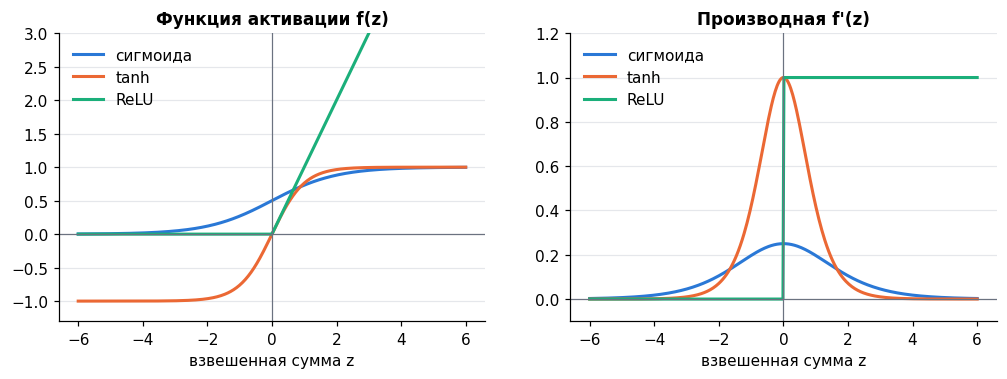

При z = 0.87: сигмоида 0.705, tanh 0.701, ReLU 0.870
Наибольшая производная: сигмоида 0.25, tanh 1.00, ReLU 1.00


In [3]:
zs = np.linspace(-6, 6, 400)
acts = {"сигмоида": (sigmoid(zs), sigmoid(zs) * (1 - sigmoid(zs))),
        "tanh": (np.tanh(zs), 1 - np.tanh(zs) ** 2),
        "ReLU": (np.maximum(zs, 0), (zs > 0).astype(float))}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for (name, (val, der)), col in zip(acts.items(), [BLUE, ORANGE, GREEN]):
    axes[0].plot(zs, val, color=col, lw=2, label=name)
    axes[1].plot(zs, der, color=col, lw=2, label=name)
axes[0].set_ylim(-1.3, 3); axes[0].set_title("Функция активации f(z)")
axes[1].set_ylim(-0.1, 1.2); axes[1].set_title("Производная f'(z)")
for ax in axes:
    ax.axhline(0, color=MUTED, lw=0.8); ax.axvline(0, color=MUTED, lw=0.8)
    ax.set_xlabel("взвешенная сумма z"); ax.grid(axis="y", color=GRID); ax.legend(frameon=False)
plt.show()

print(f"При z = {z:.2f}: сигмоида {sigmoid(z):.3f}, tanh {np.tanh(z):.3f}, ReLU {max(z, 0):.3f}")
print(f"Наибольшая производная: сигмоида {acts['сигмоида'][1].max():.2f}, tanh {acts['tanh'][1].max():.2f}, ReLU {acts['ReLU'][1].max():.2f}")

**Что видно на рисунке.** Сигмоида и tanh при больших по модулю $z$ выходят на плато. При $z=0.87$ из части 1 сигмоида и tanh случайно дают близкие значения 0.705 и 0.701, ReLU возвращает само число 0.87. Их производные там близки к нулю: нейрон в таком состоянии называют насыщенным, и сигнал об ошибке через него почти не проходит. Наибольшая производная сигмоиды равна 0.25, у tanh она равна 1. У ReLU производная равна 1 при любом положительном $z$, поэтому в глубоких сетях её используют чаще всего.

## Часть 3. Нейрон как прямая

Если входов два, уравнение $w_1x_1+w_2x_2+b=0$ задаёт прямую на плоскости. По одну сторону от неё $z>0$, по другую $z<0$. Нейрон с сигмоидой выдаёт значения больше 0.5 с одной стороны и меньше 0.5 с другой. Вектор весов $w$ перпендикулярен прямой, смещение $b$ сдвигает её.

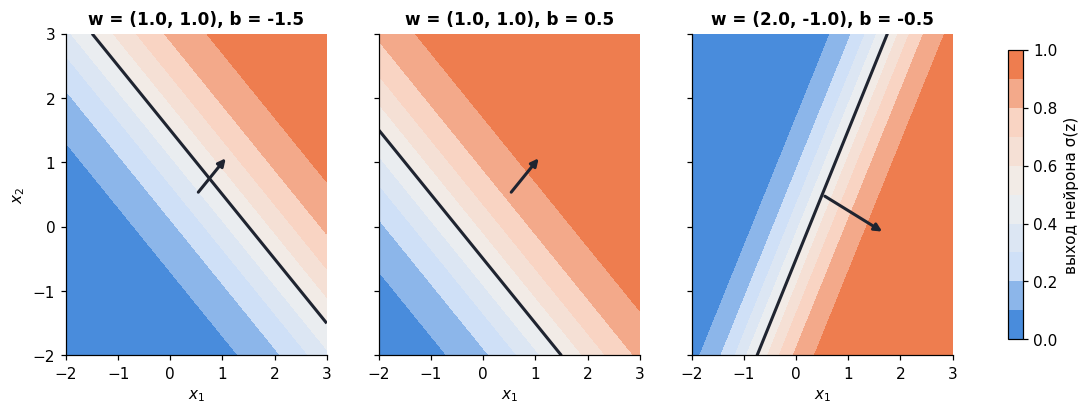

In [4]:
gx, gy = np.meshgrid(np.linspace(-2, 3, 200), np.linspace(-2, 3, 200))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharex=True, sharey=True)
for ax, (w2, b2) in zip(axes, [((1.0, 1.0), -1.5), ((1.0, 1.0), 0.5), ((2.0, -1.0), -0.5)]):
    out = sigmoid(w2[0] * gx + w2[1] * gy + b2)
    im = ax.contourf(gx, gy, out, levels=np.linspace(0, 1, 11), cmap=DIV)
    ax.contour(gx, gy, out, levels=[0.5], colors="#1f2430", linewidths=2)
    ax.annotate("", xy=(0.5 + 0.6 * w2[0], 0.5 + 0.6 * w2[1]), xytext=(0.5, 0.5), arrowprops=dict(arrowstyle="-|>", lw=2, color="#1f2430"))
    ax.set_title(f"w = {w2}, b = {b2}"); ax.set_xlabel("$x_1$")
axes[0].set_ylabel("$x_2$")
fig.colorbar(im, ax=axes, label="выход нейрона σ(z)", shrink=0.9)
plt.show()

**Что видно на рисунке.** Чёрная линия показывает точки, где $z=0$ и выход равен 0.5. Стрелка показывает направление вектора весов. При изменении смещения (первая и вторая панели) прямая сдвигается параллельно себе. При изменении весов (третья панель) она поворачивается. Один нейрон всегда делит плоскость одной прямой.

## Часть 4. AND, OR, XOR

Логические функции двух входов служат простейшей проверкой того, что умеет один нейрон. Возьмём пороговую активацию: выход равен 1 при $z>0$ и 0 в остальных случаях.

| $x_1$ | $x_2$ | AND | OR | XOR |
|---|---|---|---|---|
| 0 | 0 | 0 | 0 | 0 |
| 0 | 1 | 0 | 1 | 1 |
| 1 | 0 | 0 | 1 | 1 |
| 1 | 1 | 1 | 1 | 0 |

Для AND подходят веса $w=(1,1)$ и смещение $b=-1$, для OR веса $w=(1,1)$ и смещение $b=0$. Для XOR таких весов не существует: точки с ответом 1 лежат по диагонали, и одной прямой их от точек с ответом 0 не отделить (Minsky, Papert, 1969).

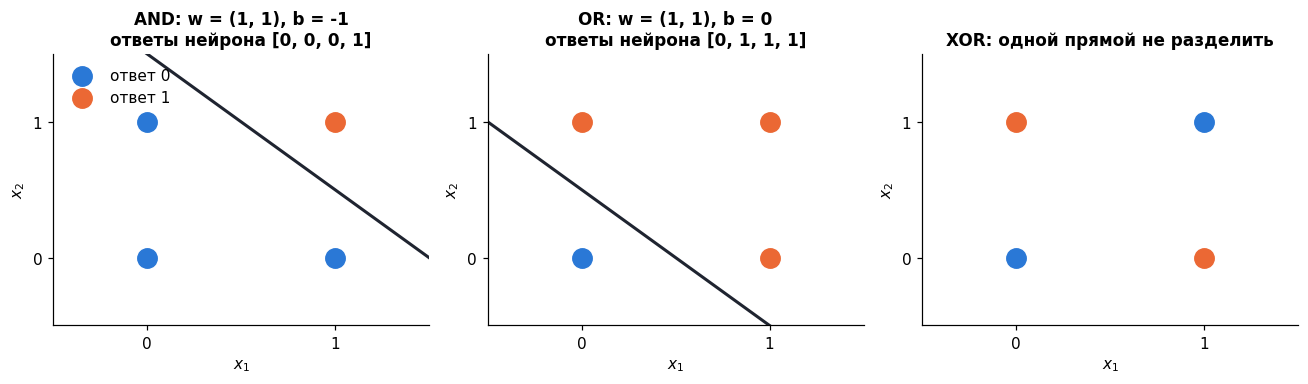

In [5]:
X4 = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
targets = {"AND": [0, 0, 0, 1], "OR": [0, 1, 1, 1], "XOR": [0, 1, 1, 0]}
neurons = {"AND": ((1, 1), -1), "OR": ((1, 1), 0)}

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (name, t) in zip(axes, targets.items()):
    t = np.array(t)
    ax.scatter(X4[t == 0, 0], X4[t == 0, 1], s=160, color=BLUE, label="ответ 0", zorder=3)
    ax.scatter(X4[t == 1, 0], X4[t == 1, 1], s=160, color=ORANGE, label="ответ 1", zorder=3)
    if name in neurons:
        (w1, w2), bb = neurons[name]
        xs = np.linspace(-0.5, 1.5, 10)
        ax.plot(xs, (-bb + 0.5 - w1 * xs) / w2, color="#1f2430", lw=2)      # прямая посередине между классами
        pred = ((X4 @ np.array([w1, w2]) + bb) > 0).astype(int)
        ax.set_title(f"{name}: w = ({w1}, {w2}), b = {bb}\nответы нейрона {pred.tolist()}")
    else:
        ax.set_title("XOR: одной прямой не разделить")
    ax.set_xlim(-0.5, 1.5); ax.set_ylim(-0.5, 1.5); ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
axes[0].legend(frameon=False, loc="upper left")
fig.tight_layout()
plt.show()

**Что видно на рисунке.** Для AND и OR прямая отделяет оранжевые точки от синих. Для XOR оранжевые точки стоят в противоположных углах квадрата, и любая прямая оставит хотя бы одну точку на чужой стороне.

### Решение: два слоя

XOR вычисляет сеть из трёх нейронов с активацией ReLU (Goodfellow и др., 2016). Два нейрона скрытого слоя получают оба входа с весами 1. У первого смещение 0, у второго $-1$:

$$h_1=\mathrm{ReLU}(x_1+x_2),\qquad h_2=\mathrm{ReLU}(x_1+x_2-1).$$

Выходной нейрон складывает их с весами 1 и $-2$: $y=h_1-2h_2$.

 x1  x2  h1  h2  y  XOR
  0   0   0   0  0    0
  0   1   1   0  1    1
  1   0   1   0  1    1
  1   1   2   1  0    0


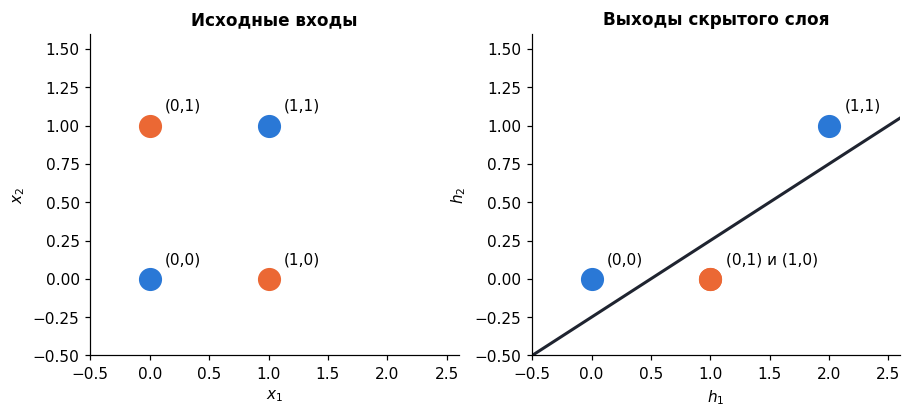

In [6]:
W = np.array([[1, 1], [1, 1]])      # веса скрытого слоя: строка соответствует нейрону
b_h = np.array([0, -1])             # смещения скрытого слоя
u = np.array([1, -2])               # веса выходного нейрона

H = np.maximum(X4 @ W.T + b_h, 0)   # выходы скрытого слоя для четырёх входов
y_xor = H @ u
print(pd.DataFrame({"x1": X4[:, 0], "x2": X4[:, 1], "h1": H[:, 0], "h2": H[:, 1], "y": y_xor, "XOR": targets["XOR"]}).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8))
t = np.array(targets["XOR"])
for ax, pts, labels, title in [(axes[0], X4, ("$x_1$", "$x_2$"), "Исходные входы"),
                               (axes[1], H, ("$h_1$", "$h_2$"), "Выходы скрытого слоя")]:
    for p, cls, name in zip(pts, t, ["(0,0)", "(0,1)", "(1,0)", "(1,1)"]):
        ax.scatter(*p, s=200, color=ORANGE if cls else BLUE, zorder=3)
    for p in np.unique(pts, axis=0):
        names = [n for q, n in zip(pts, ["(0,0)", "(0,1)", "(1,0)", "(1,1)"]) if (q == p).all()]
        ax.annotate(" и ".join(names), p, textcoords="offset points", xytext=(10, 10))
    ax.set_xlabel(labels[0]); ax.set_ylabel(labels[1]); ax.set_title(title)
    ax.set_xlim(-0.5, 2.6); ax.set_ylim(-0.5, 1.6)
xs = np.linspace(-0.5, 2.6, 10)
axes[1].plot(xs, (xs - 0.5) / 2, color="#1f2430", lw=2)        # прямая h1 - 2*h2 = 0.5
plt.show()

**Что видно на рисунке.** Скрытый слой переносит точки в новое пространство. Входы (0,1) и (1,0) попадают в одну точку $(1,0)$, вход (1,1) уходит в точку $(2,1)$. В новых координатах оранжевая точка отделяется от синих одной прямой, и выходной нейрон с этим справляется. Скрытый слой строит новое представление входа, в котором задача становится линейно разделимой. Без нелинейной активации этого бы не произошло: два линейных слоя подряд равны одному линейному слою.

## Часть 5. Сеть в матричном виде

В сети прямого распространения (feedforward network) нейроны собраны в слои, и каждый слой передаёт выходы следующему. Веса слоя удобно записать матрицей $W$: строка $j$ содержит веса нейрона $j$. Тогда весь слой вычисляется одной формулой:

$$h=f(Wx+b),$$

где $x$ обозначает вектор входов слоя, $b$ вектор смещений, $f$ применяется к каждому элементу. Сеть с одним скрытым слоем для задачи классификации:

$$h=\mathrm{ReLU}(Wx+b),\qquad z=Uh,\qquad \hat y=\mathrm{softmax}(z).$$

Функция **softmax** превращает вектор оценок $z$ в распределение вероятностей по классам:

$$\mathrm{softmax}(z)_i=\frac{e^{z_i}}{\sum_{j}e^{z_j}}.$$

Все значения положительны и в сумме дают единицу, наибольшая оценка получает наибольшую вероятность.

Оценки z:       [ 0.6  1.1 -1.5  1.2  3.2 -1.1]
softmax(z):     [0.055 0.09  0.007 0.1   0.738 0.01 ]  сумма = 1.0

Прямой проход для x = [0.5 0.6 0.1]
  размер W: (4, 3)  скрытый слой h = [0.23  0.598 1.203 0.   ]
  размер U: (2, 4)  оценки z = [-3.163 -1.138]  вероятности = [0.117 0.883]


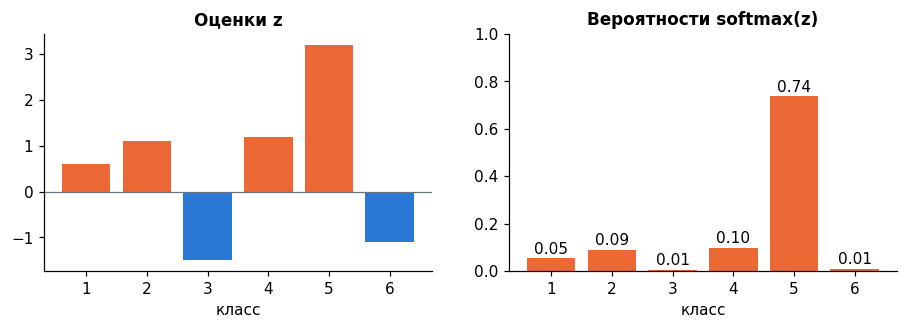

In [7]:
def softmax(z):
    e = np.exp(z - z.max())          # вычитание максимума защищает от переполнения и не меняет результат
    return e / e.sum()


z_book = np.array([0.6, 1.1, -1.5, 1.2, 3.2, -1.1])      # пример из главы 6
p_book = softmax(z_book)
print("Оценки z:      ", z_book)
print("softmax(z):    ", np.round(p_book, 3), " сумма =", round(p_book.sum(), 3))

rng = np.random.RandomState(SEED)
W1, b1 = rng.randn(4, 3), np.zeros(4)      # скрытый слой: 3 входа, 4 нейрона
U = rng.randn(2, 4)                        # выходной слой: 2 класса
h = np.maximum(W1 @ x + b1, 0)
print("\nПрямой проход для x =", x)
print("  размер W:", W1.shape, " скрытый слой h =", np.round(h, 3))
print("  размер U:", U.shape, " оценки z =", np.round(U @ h, 3), " вероятности =", np.round(softmax(U @ h), 3))

fig, axes = plt.subplots(1, 2, figsize=(10, 2.8))
axes[0].bar(range(1, 7), z_book, color=[BLUE if v < 0 else ORANGE for v in z_book]); axes[0].axhline(0, color=MUTED, lw=0.8)
axes[0].set_title("Оценки z"); axes[0].set_xlabel("класс")
axes[1].bar(range(1, 7), p_book, color=ORANGE); axes[1].set_title("Вероятности softmax(z)"); axes[1].set_xlabel("класс"); axes[1].set_ylim(0, 1)
for i, v in enumerate(p_book):
    axes[1].text(i + 1, v + 0.02, f"{v:.2f}", ha="center")
plt.show()

**Что видно на рисунке.** Оценки могут быть любыми числами, в том числе отрицательными. После softmax класс 5 с оценкой 3.2 получает вероятность 0.74. Разница оценок в две единицы между классами 5 и 4 превращается в отношение вероятностей $e^{2}\approx 7.4$: softmax усиливает различия.

## Часть 6. Функция потерь и граф вычислений

Обучение подбирает веса так, чтобы ответы сети были близки к правильным. Близость измеряет функция потерь. Для классификации берут **кросс-энтропию**: минус логарифм вероятности, которую сеть дала правильному классу $c$,

$$L=-\ln\hat y_c.$$

Если сеть уверена в правильном ответе, $\hat y_c$ близко к 1 и потери близки к нулю. Если сеть дала правильному классу малую вероятность, потери велики.

Веса меняют **градиентным спуском**: вычисляют производную потерь по каждому весу и сдвигают вес в сторону убывания потерь,

$$w\leftarrow w-\eta\,\frac{\partial L}{\partial w},$$

где $\eta$ обозначает скорость обучения (learning rate).

Производные по всем весам вычисляет алгоритм **обратного распространения ошибки** (backpropagation). Вычисление записывается графом, производные проходят по графу от выхода к входам по цепному правилу. Пример из главы 6: $L=c\,(a+2b)$ при $a=3$, $b=1$, $c=-2$.

- Прямой проход: $d=2b=2$, $e=a+d=5$, $L=c\cdot e=-10$.
- Обратный проход: $\partial L/\partial e=c=-2$, $\partial L/\partial c=e=5$, $\partial L/\partial a=\partial L/\partial e\cdot 1=-2$, $\partial L/\partial b=\partial L/\partial e\cdot 1\cdot 2=-4$.

PyTorch строит такой граф автоматически и выполняет обратный проход методом `backward`.

Прямой проход: d = 2, e = 5, L = -10
Обратный проход: dL/da = -2, dL/db = -4, dL/dc = 5

Нейрон из части 1, правильный ответ y = 1
  потери L = -ln(0.705) = 0.350
  градиент по весам, autograd:         [-0.1476 -0.1772 -0.0295]
  градиент по формуле (sigma(z)-1)*x:  [-0.1476 -0.1772 -0.0295]


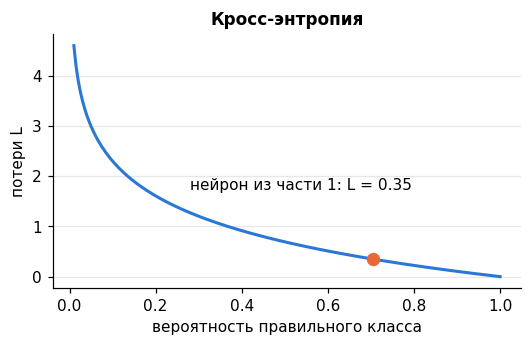

In [8]:
a = torch.tensor(3.0, requires_grad=True)
bb = torch.tensor(1.0, requires_grad=True)
c = torch.tensor(-2.0, requires_grad=True)

d = 2 * bb
e = a + d
L = c * e
L.backward()                         # обратный проход по графу вычислений
print(f"Прямой проход: d = {d.item():.0f}, e = {e.item():.0f}, L = {L.item():.0f}")
print(f"Обратный проход: dL/da = {a.grad.item():.0f}, dL/db = {bb.grad.item():.0f}, dL/dc = {c.grad.item():.0f}")

# Потери одного нейрона с сигмоидой: производная по весам равна (sigma(z) - y) * x
w_t = torch.tensor(w, requires_grad=True)
z_t = w_t @ torch.tensor(x) + b
loss = -torch.log(torch.sigmoid(z_t))          # кросс-энтропия при правильном ответе y = 1
loss.backward()
print("\nНейрон из части 1, правильный ответ y = 1")
print(f"  потери L = -ln({sigmoid(z):.3f}) = {loss.item():.3f}")
print("  градиент по весам, autograd:        ", np.round(w_t.grad.numpy(), 4))
print("  градиент по формуле (sigma(z)-1)*x: ", np.round((sigmoid(z) - 1) * x, 4))

ps = np.linspace(0.01, 1, 200)
fig, ax = plt.subplots(figsize=(5.5, 3))
ax.plot(ps, -np.log(ps), color=BLUE, lw=2)
ax.scatter([sigmoid(z)], [-np.log(sigmoid(z))], color=ORANGE, s=60, zorder=3)
ax.annotate(f"нейрон из части 1: L = {-np.log(sigmoid(z)):.2f}", (sigmoid(z), -np.log(sigmoid(z))), textcoords="offset points", xytext=(-120, 45))
ax.set_xlabel("вероятность правильного класса"); ax.set_ylabel("потери L"); ax.set_title("Кросс-энтропия")
ax.grid(axis="y", color=GRID)
plt.show()

**Что видно на рисунке.** Потери быстро растут, когда вероятность правильного класса приближается к нулю, и равны нулю при вероятности 1. Значения производных, посчитанные PyTorch, совпали с расчётом вручную: $-2$, $-4$ и 5 для графа из книги. Для нейрона градиент по весам равен $(\sigma(z)-y)\,x$: он пропорционален ошибке и входу.

## Часть 7. Обучение сети на двумерных данных

Данные состоят из двух изогнутых групп точек («две луны»). Одной прямой они не разделяются. Сеть с одним скрытым слоем обучается градиентным спуском: на каждом шаге выполняются прямой проход, расчёт потерь, обратный проход и сдвиг весов.

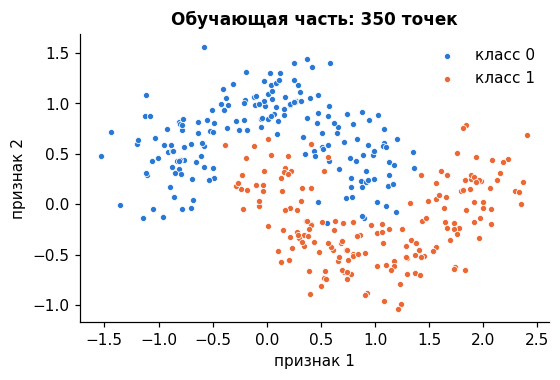

In [9]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=500, noise=0.22, random_state=SEED)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=SEED)

fig, ax = plt.subplots(figsize=(5.5, 3.4))
for cls, col in [(0, BLUE), (1, ORANGE)]:
    ax.scatter(X_train[y_train == cls, 0], X_train[y_train == cls, 1], s=16, color=col, edgecolor="white", linewidth=0.5, label=f"класс {cls}")
ax.set_xlabel("признак 1"); ax.set_ylabel("признак 2"); ax.set_title(f"Обучающая часть: {len(y_train)} точек"); ax.legend(frameon=False)
plt.show()

In [10]:
def make_mlp(n_hidden, n_layers=1, activation=nn.ReLU):
    # Сеть прямого распространения: 2 входа, n_layers скрытых слоёв по n_hidden нейронов, 2 выхода (оценки классов).
    # activation=None даёт сеть без нелинейности.
    layers, n_in = [], 2
    for _ in range(n_layers):
        layers.append(nn.Linear(n_in, n_hidden))
        if activation is not None:
            layers.append(activation())
        n_in = n_hidden
    layers.append(nn.Linear(n_in, 2))
    return nn.Sequential(*layers)


def train_mlp(model, X, y, lr=0.1, epochs=500, X_val=None, y_val=None, optimizer="sgd", weight_decay=0.0):
    # Обучение на всей выборке сразу. Возвращает историю потерь на обучении и на проверочной части.
    X, y = torch.as_tensor(X, dtype=torch.float32), torch.as_tensor(y, dtype=torch.long)
    if X_val is not None:
        X_val, y_val = torch.as_tensor(X_val, dtype=torch.float32), torch.as_tensor(y_val, dtype=torch.long)
    opt = (torch.optim.SGD(model.parameters(), lr=lr, weight_decay=weight_decay) if optimizer == "sgd"
           else torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay))
    history = {"train": [], "val": []}
    for _ in range(epochs):
        loss = F.cross_entropy(model(X), y)          # прямой проход и функция потерь
        opt.zero_grad()
        loss.backward()                              # обратный проход: градиенты по всем весам
        opt.step()                                   # шаг против градиента
        history["train"].append(loss.item())
        if X_val is not None:
            with torch.no_grad():
                history["val"].append(F.cross_entropy(model(X_val), y_val).item())
    return history


def mlp_accuracy(model, X, y):
    with torch.no_grad():
        pred = model(torch.as_tensor(X, dtype=torch.float32)).argmax(1).numpy()
    return float((pred == np.asarray(y)).mean())


def plot_mlp_boundary(ax, model, X, y, title="", lim=(-1.8, 2.8, -1.5, 2.0)):
    # Закрашивает плоскость вероятностью класса 1 и рисует границу, на которой она равна 0.5.
    gx, gy = np.meshgrid(np.linspace(lim[0], lim[1], 250), np.linspace(lim[2], lim[3], 250))
    grid = torch.tensor(np.c_[gx.ravel(), gy.ravel()], dtype=torch.float32)
    with torch.no_grad():
        p = F.softmax(model(grid), dim=1)[:, 1].numpy().reshape(gx.shape)
    ax.contourf(gx, gy, p, levels=np.linspace(0, 1, 11), cmap=DIV, alpha=0.9)
    ax.contour(gx, gy, p, levels=[0.5], colors="#1f2430", linewidths=1.8)
    for cls, col in [(0, BLUE), (1, ORANGE)]:
        ax.scatter(X[y == cls, 0], X[y == cls, 1], s=16, color=col, edgecolor="white", linewidth=0.5)
    ax.set_xlim(lim[0], lim[1]); ax.set_ylim(lim[2], lim[3]); ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([])

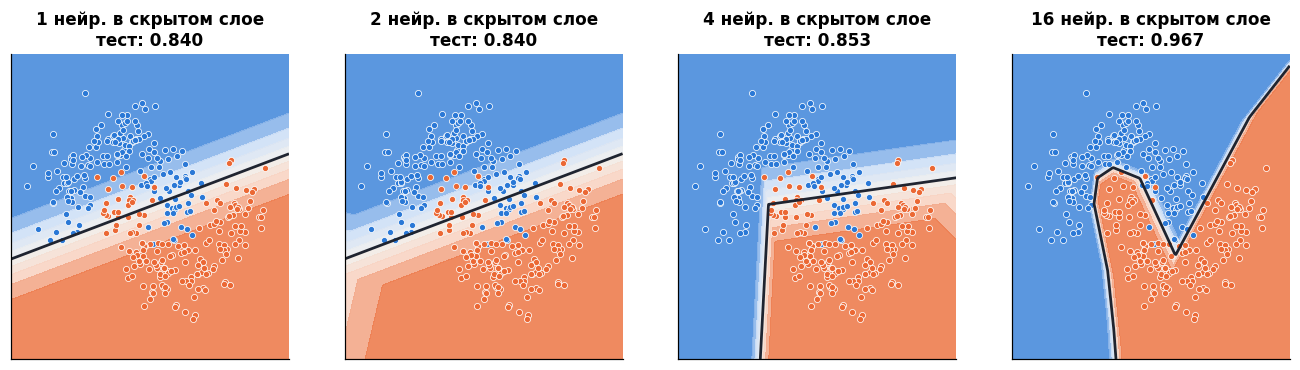

    доля верных, обучение  доля верных, тест  число параметров
1                   0.863              0.840               7.0
2                   0.863              0.840              12.0
4                   0.891              0.853              22.0
16                  0.974              0.967              82.0


In [11]:
sizes = [1, 2, 4, 16]
fig, axes = plt.subplots(1, len(sizes), figsize=(15, 3.6))
size_results = {}
for ax, n in zip(axes, sizes):
    set_seed()
    model = make_mlp(n)
    hist = train_mlp(model, X_train, y_train, lr=0.03, epochs=800, optimizer="adam")
    size_results[n] = (mlp_accuracy(model, X_train, y_train), mlp_accuracy(model, X_test, y_test), sum(p.numel() for p in model.parameters()))
    plot_mlp_boundary(ax, model, X_train, y_train, f"{n} нейр. в скрытом слое\nтест: {size_results[n][1]:.3f}")
plt.show()
print(pd.DataFrame(size_results, index=["доля верных, обучение", "доля верных, тест", "число параметров"]).T.round(3).to_string())

**Что видно на рисунке.** Плоскость закрашена вероятностью класса 1, чёрная линия показывает границу между классами. Сеть с одним нейроном в скрытом слое проводит прямую, как логистическая регрессия. С ростом числа нейронов у границы появляются изломы, и при 16 нейронах она повторяет форму групп. Число нейронов скрытого слоя определяет, насколько сложную границу сеть способна построить.

### Роль нелинейности

Та же сеть без функции активации остаётся линейной моделью при любом числе нейронов.

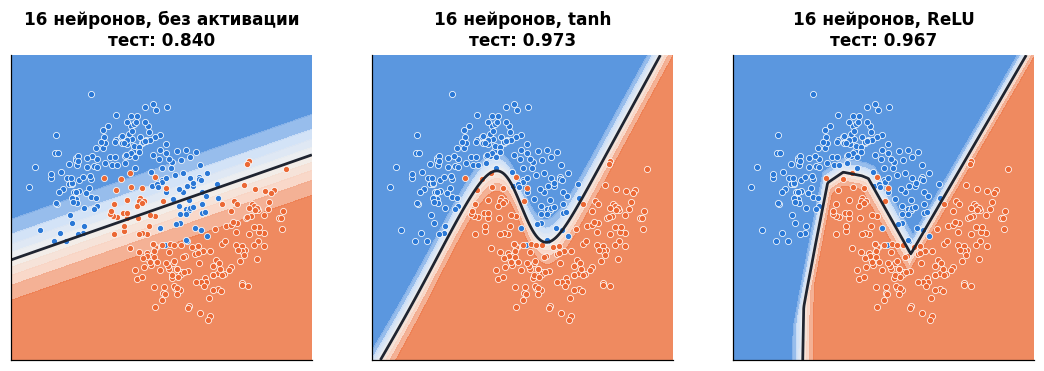

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
act_results = {}
for ax, (name, act) in zip(axes, [("без активации", None), ("tanh", nn.Tanh), ("ReLU", nn.ReLU)]):
    set_seed()
    model = make_mlp(16, activation=act)
    train_mlp(model, X_train, y_train, lr=0.5, epochs=1500)
    act_results[name] = mlp_accuracy(model, X_test, y_test)
    plot_mlp_boundary(ax, model, X_train, y_train, f"16 нейронов, {name}\nтест: {act_results[name]:.3f}")
plt.show()

**Что видно на рисунке.** Без активации 16 нейронов дают прямую границу: произведение двух матриц весов остаётся одной матрицей. С tanh и ReLU граница изгибается. Нелинейная функция активации делает сеть сильнее линейной модели.

## Часть 8. Скорость обучения и переобучение

### Скорость обучения

Скорость обучения $\eta$ задаёт длину шага градиентного спуска. При слишком малом значении потери убывают медленно. При слишком большом шаг перескакивает минимум, и потери колеблются или растут.

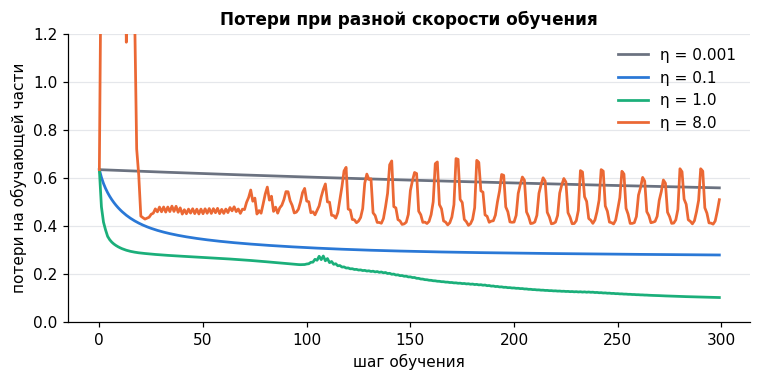

Потери после 300 шагов: {0.001: 0.559, 0.1: 0.279, 1.0: 0.102, 8.0: 0.51}


In [13]:
fig, ax = plt.subplots(figsize=(8, 3.4))
lr_results = {}
for lr, col in zip([0.001, 0.1, 1.0, 8.0], [MUTED, BLUE, GREEN, ORANGE]):
    set_seed()
    model = make_mlp(16)
    hist = train_mlp(model, X_train, y_train, lr=lr, epochs=300)
    lr_results[lr] = hist["train"][-1]
    ax.plot(hist["train"], color=col, lw=1.8, label=f"η = {lr}")
ax.set_ylim(0, 1.2); ax.set_xlabel("шаг обучения"); ax.set_ylabel("потери на обучающей части")
ax.set_title("Потери при разной скорости обучения"); ax.legend(frameon=False); ax.grid(axis="y", color=GRID)
plt.show()
print("Потери после 300 шагов:", {k: round(v, 3) for k, v in lr_results.items()})

**Что видно на рисунке.** При $\eta=0.001$ за 300 шагов потери снизились незначительно, с 0.63 до 0.56. При $\eta=0.1$ и $\eta=1$ они убывают, причём при большем значении быстрее. При $\eta=8$ кривая скачет: шаги слишком длинные. Скорость обучения подбирают по такой кривой потерь.

### Переобучение

Сеть с большим числом весов способна запомнить обучающие примеры вместе с шумом. Тогда потери на обучающей части продолжают падать, на новых данных они растут. Это называется переобучением. Его видно по разрыву между двумя кривыми потерь: на обучающей и на проверочной части.

Ниже взята маленькая зашумлённая выборка из 60 точек и сеть с двумя скрытыми слоями по 64 нейрона.

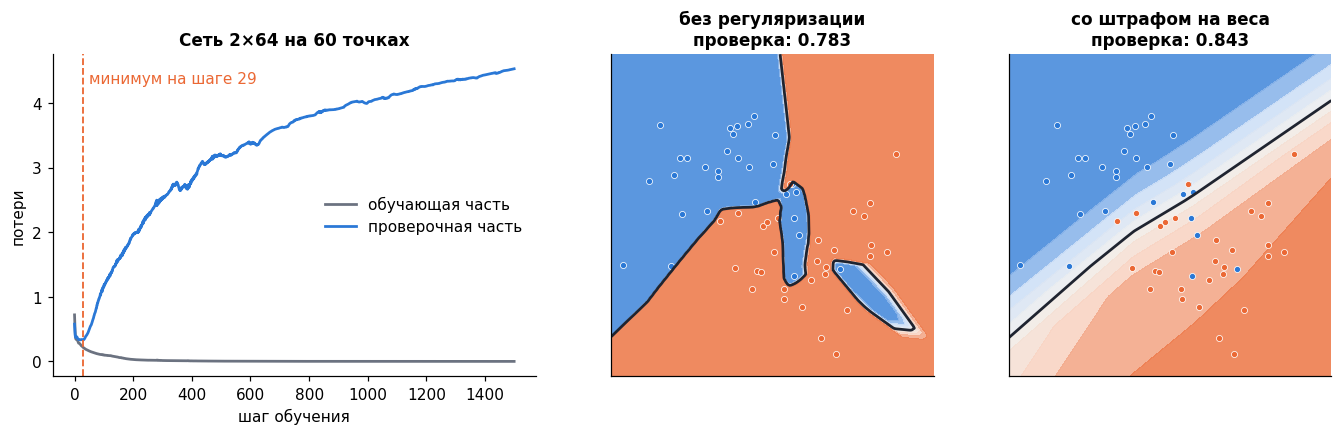

Без регуляризации: потери на обучении 0.000, на проверке 4.528 (минимум 0.332 на шаге 29)
Со штрафом на веса: потери на обучении 0.314, на проверке 0.361


In [14]:
X_small, y_small = make_moons(n_samples=60, noise=0.35, random_state=1)
X_val, y_val = make_moons(n_samples=1000, noise=0.35, random_state=2)

set_seed()
big = make_mlp(64, n_layers=2)
hist_big = train_mlp(big, X_small, y_small, lr=0.01, epochs=1500, X_val=X_val, y_val=y_val, optimizer="adam")
set_seed()
reg = make_mlp(64, n_layers=2)
hist_reg = train_mlp(reg, X_small, y_small, lr=0.01, epochs=1500, X_val=X_val, y_val=y_val, optimizer="adam", weight_decay=0.02)
best = int(np.argmin(hist_big["val"]))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw={"width_ratios": [1.5, 1, 1]})
ax = axes[0]
ax.plot(hist_big["train"], color=MUTED, lw=1.8, label="обучающая часть")
ax.plot(hist_big["val"], color=BLUE, lw=1.8, label="проверочная часть")
ax.axvline(best, color=ORANGE, ls="--", lw=1.2); ax.text(best + 20, 0.95 * max(hist_big["val"]), f"минимум на шаге {best}", color=ORANGE)
ax.set_xlabel("шаг обучения"); ax.set_ylabel("потери"); ax.set_title("Сеть 2×64 на 60 точках"); ax.legend(frameon=False, loc="center right")
plot_mlp_boundary(axes[1], big, X_small, y_small, f"без регуляризации\nпроверка: {mlp_accuracy(big, X_val, y_val):.3f}")
plot_mlp_boundary(axes[2], reg, X_small, y_small, f"со штрафом на веса\nпроверка: {mlp_accuracy(reg, X_val, y_val):.3f}")
plt.show()
print(f"Без регуляризации: потери на обучении {hist_big['train'][-1]:.3f}, на проверке {hist_big['val'][-1]:.3f} (минимум {min(hist_big['val']):.3f} на шаге {best})")
print(f"Со штрафом на веса: потери на обучении {hist_reg['train'][-1]:.3f}, на проверке {hist_reg['val'][-1]:.3f}")

**Что видно на рисунке.** Слева потери на обучающей части падают почти до нуля, потери на проверочной части после минимума растут. Граница на средней панели огибает отдельные точки: сеть запомнила шум. Два простых средства показаны на рисунке. Обучение останавливают на шаге с наименьшими потерями на проверочной части (ранняя остановка). К потерям добавляют штраф за большие веса (параметр `weight_decay`), и граница на правой панели получается более гладкой. Третье распространённое средство называется dropout: при обучении случайная часть нейронов отключается на каждом шаге.

## Итог

- Нейрон вычисляет взвешенную сумму входов со смещением и применяет функцию активации.
- Один нейрон делит пространство входов одной прямой. XOR ему недоступен.
- Скрытый слой с нелинейной активацией строит новое представление входа, в котором задача решается линейно.
- Softmax превращает оценки в вероятности, кросс-энтропия измеряет ошибку.
- Сеть обучается градиентным спуском, градиенты вычисляются обратным распространением ошибки по графу вычислений.
- Качество контролируют по проверочной части: по ней подбирают скорость обучения и замечают переобучение.

Следующий блокнот переносит эти идеи на тексты: на вход сети подаются эмбеддинги слов, для последовательностей используются рекуррентные сети.